# Regresión: XGBoost

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "xgboost"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,XGBoost
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |
| **d) Pérdida Poisson** | `bdi_total` sin transformar, con pérdida (deviance) Poisson: `objective="count:poisson"` | Predicción directa en la escala de la media |

En las cuatro, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** En sqrt y log1p el modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. En los árboles los residuos de entrenamiento son más pequeños que los de datos nuevos (el modelo se ajusta a ellos), así que la corrección es parcial.

La **pérdida Poisson** no tiene este problema: no transforma $y$, sino que ajusta la media directamente con una pérdida pensada para conteos no negativos y asimétricos, así que no necesita smearing. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Mismos rangos que en la clasificación (versión `Regressor`). Se exploraron 25 combinaciones por variante: complejidad (profundidad de 2 a 6, entre 100 y 600 árboles, `min_child_weight` de 1 a 10), muestreo de filas y columnas (0.6 a 1) y tasa de aprendizaje en escala logarítmica (0.01 a 0.2).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 100 y 600
max_depth,entero entre 2 y 6
learning_rate,log-uniforme entre 0.01 y 0.2
subsample,uniforme entre 0.6 y 1
colsample_bytree,uniforme entre 0.6 y 1
min_child_weight,entero entre 1 y 10


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.8876 ± 0.4884  R² = 0.2040  (7 s)
✓ sqrt + smearing    RMSE = 6.8796 ± 0.5001  R² = 0.2059  (4 s)
✓ log1p + smearing   RMSE = 6.8919 ± 0.4821  R² = 0.2028  (4 s)
✓ Pérdida Poisson    RMSE = 6.8942 ± 0.5080  R² = 0.2027  (4 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.888 ± 0.488,4.904 ± 0.182,0.204 ± 0.015,7.0
sqrt + smearing,6.880 ± 0.500,4.859 ± 0.189,0.206 ± 0.019,4.0
log1p + smearing,6.892 ± 0.482,4.874 ± 0.184,0.203 ± 0.019,4.0
Pérdida Poisson,6.894 ± 0.508,4.911 ± 0.190,0.203 ± 0.017,4.0


sqrt obtiene el menor RMSE (6.880 ± 0.500) y el mayor R² (0.206), seguida del nativo (6.888, R² = 0.204), log1p (6.892) y la pérdida Poisson (6.894). Las cuatro variantes están a menos de 0.015 puntos entre sí. sqrt y log1p reducen algo el MAE (4.859 y 4.874, frente a 4.904 del nativo).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample
Variante,,,,,,
Nativo,0.7434,0.01415,2,8,367,0.7324
sqrt + smearing,0.8832,0.01064,3,8,591,0.9754
log1p + smearing,0.7297,0.01442,2,7,289,0.6440
Pérdida Poisson,0.6944,0.02154,4,9,306,0.7710


Como en la clasificación, todas las variantes eligen árboles muy poco profundos (`max_depth` de 2 a 4), tasas de aprendizaje bajas (0.011 a 0.022) y un `min_child_weight` alto (7 a 9). La señal es simple y está dominada por efectos principales. La pérdida Poisson es la única que usa árboles de profundidad 4.

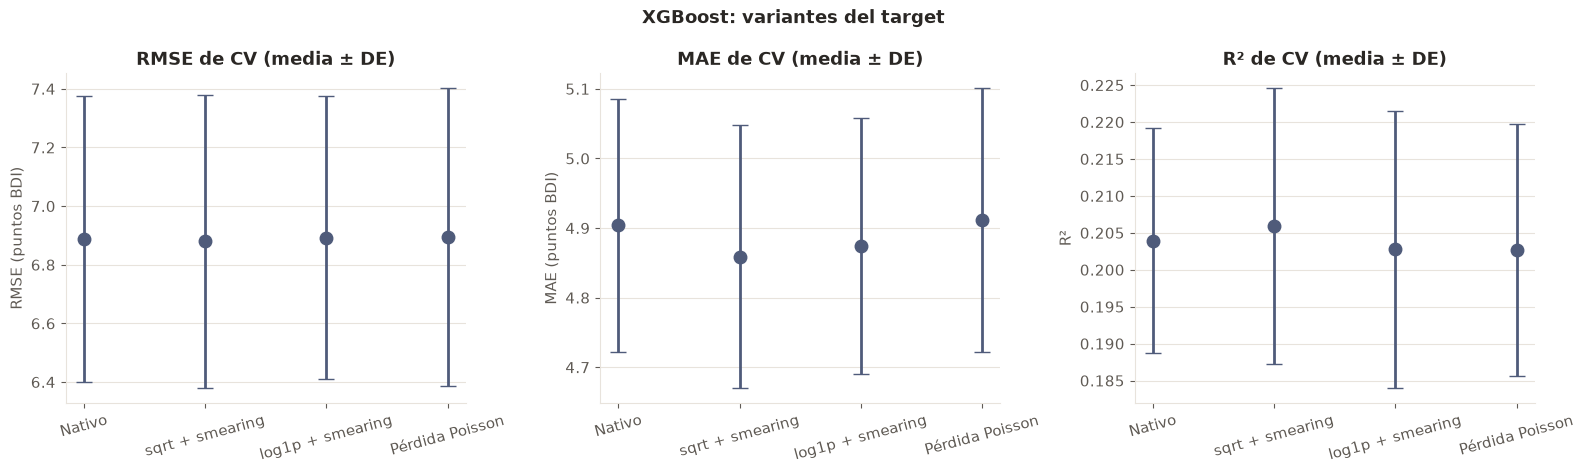

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica muestra cuatro variantes equivalentes, con barras de desviación que se solapan por completo.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada (sqrt o log1p) se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.808,-1.494,7.056,4.644,0.170
Con smearing,7.152,-0.149,6.898,4.859,0.207


Sin smearing, la media predicha con sqrt es 5.81, 1.49 puntos por debajo de la real; con la corrección queda en 7.15. El RMSE baja de 7.056 a 6.898 y el R² sube de 0.170 a 0.207. Queda un sesgo de −0.15 puntos porque los residuos de entrenamiento del boosting son algo menores que los de datos nuevos.

### Selección del Mejor Modelo XGBoost

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p < Poisson) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,XGBoost
Variante ganadora,Nativo
RMSE de CV,6.8876 ± 0.4884
MAE de CV,4.9039 ± 0.1819
R² de CV,0.2040 ± 0.0152
Hiperparámetros,"colsample_bytree=0.7434, learning_rate=0.01415, max_depth=2, min_child_weight=8, n_estimators=367, subsample=0.7324"
Criterio,"El menor RMSE medio de CV es el de 'sqrt + smearing' (6.8796 ± 0.5001), pero 'Nativo' es más simple y su RMSE (6.8876) está a solo 0.0080 puntos, menos que la desviación estándar de CV de la ganadora (0.5001). Por la regla de empate se elige 'Nativo'."


sqrt tiene el menor RMSE medio (6.8796), pero el nativo está a solo 0.008 puntos (desviación entre folds: 0.500). Por la regla de empate se elige el nativo.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/xgboost: resultados_cv.csv, ganador.json y xgboost_nativo.joblib
